<a href="https://colab.research.google.com/github/ali-liyakat/100_days_Deep_Learning/blob/main/06_CNN/10_Functional_API_VGG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-Task Learning with VGG16 — Age and Gender Prediction

This notebook uses the **Keras Functional API** and a pretrained **VGG16** backbone to predict age and gender from facial images in the UTKFace dataset.

**Objectives:**
- Apply transfer learning using pretrained VGG16.
- Build a two-branch architecture for age regression and gender classification.
- Train a shared feature extractor with two task-specific output heads.
- Evaluate and visualize age and gender prediction performance.

In [1]:
%pip install -q -U kagglehub

import kagglehub
from pathlib import Path

# Download UTKFace dataset
dataset_path = Path(
    kagglehub.dataset_download("jangedoo/utkface-new")
)

print("Dataset downloaded to:", dataset_path)

# List downloaded files and folders
for item in list(dataset_path.iterdir())[:20]:
    print(item.name)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.4/40.4 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.3/73.3 kB 952.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 290.9/290.9 kB 842.9 kB/s eta 0:00:00
Using Colab cache for faster access to the 'utkface-new' dataset.
Dataset downloaded to: /kaggle/input/utkface-new
UTKFace
utkface_aligned_cropped
crop_part1


In [3]:
from pathlib import Path
import pandas as pd

age, gender, img_path = [], [], []

for path in Path(dataset_path).rglob("*"):
    if path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
        try:
            parts = path.name.split("_")
            age.append(int(parts[0]))
            gender.append(int(parts[1]))
            img_path.append(str(path))
        except (ValueError, IndexError):
            continue

df = pd.DataFrame({
    "age": age,
    "gender": gender,
    "img": img_path
})

print(df.shape)
df.head()

(66976, 3)


,age,gender,img
0,26,0,/kaggle/input/utkface-new/UTKFace/26_0_2_20170...
1,22,1,/kaggle/input/utkface-new/UTKFace/22_1_1_20170...
2,21,1,/kaggle/input/utkface-new/UTKFace/21_1_3_20170...
3,28,0,/kaggle/input/utkface-new/UTKFace/28_0_0_20170...
4,17,1,/kaggle/input/utkface-new/UTKFace/17_1_4_20170...


In [4]:
import os

print("DataFrame shape:", df.shape)
print("First image path:", df["img"].iloc[0])
print("Image exists:", os.path.exists(df["img"].iloc[0]))

DataFrame shape: (66976, 3)
First image path: /kaggle/input/utkface-new/UTKFace/26_0_2_20170104023102422.jpg.chip.jpg
Image exists: True


In [5]:
# Check missing values
print("Missing values:\n", df.isnull().sum())

# Check age distribution
print("\nAge statistics:")
print(df["age"].describe())

# Check gender distribution
print("\nGender counts:")
print(df["gender"].value_counts())

# Check duplicate image paths
print("\nDuplicate image paths:", df["img"].duplicated().sum())

Missing values:
 age       0
gender    0
img       0
dtype: int64

Age statistics:
count    66976.000000
mean        32.169792
std         21.502316
min          1.000000
25%         18.000000
50%         28.000000
75%         45.000000
max        116.000000
Name: age, dtype: float64

Gender counts:
gender
0    33526
1    33448
3        2
Name: count, dtype: int64

Duplicate image paths: 0


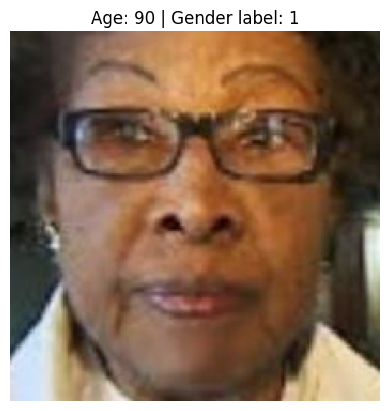

In [6]:
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img

sample = df.sample(1, random_state=42).iloc[0]

img = load_img(sample["img"], target_size=(224, 224))

plt.imshow(img)
plt.title(f"Age: {sample['age']} | Gender label: {sample['gender']}")
plt.axis("off")
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

# Keep only valid rows
df = df.dropna(subset=["age", "gender", "img"]).copy()
df = df[df["gender"].isin([0, 1])]
df = df[df["age"].between(0, 116)]
df = df[df["img"].apply(os.path.isfile)].reset_index(drop=True)

# Split: 80% training, 10% validation, 10% testing
train_df, temp_df = train_test_split(
    df, test_size=0.20, random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 53579
Validation: 6697
Testing: 6698


In [8]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
MAX_AGE = 116
AUTOTUNE = tf.data.AUTOTUNE

In [9]:
def load_image(path, age, gender):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = preprocess_input(image)

    # Normalize age to the range 0–1
    age = tf.cast(age, tf.float32) / MAX_AGE
    gender = tf.cast(gender, tf.float32)

    return image, {
        "age_output": tf.reshape(age, (1,)),
        "gender_output": tf.reshape(gender, (1,))
    }


def make_dataset(dataframe, training=False):
    paths = dataframe["img"].values
    ages = dataframe["age"].values.astype("float32")
    genders = dataframe["gender"].values.astype("float32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, ages, genders)
    )

    if training:
        dataset = dataset.shuffle(
            min(len(dataframe), 10000),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Datasets ready!")

Datasets ready!


In [10]:
# Load pretrained VGG16 without its original classifier
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False

# Shared input and feature extractor
inputs = layers.Input(shape=(224, 224, 3), name="image_input")

features = base_model(inputs, training=False)
features = layers.GlobalAveragePooling2D()(features)

# Branch 1: Age regression
age_branch = layers.Dense(256, activation="relu")(features)
age_branch = layers.Dropout(0.3)(age_branch)
age_output = layers.Dense(
    1, activation="sigmoid", name="age_output"
)(age_branch)

# Branch 2: Gender classification
gender_branch = layers.Dense(128, activation="relu")(features)
gender_branch = layers.Dropout(0.3)(gender_branch)
gender_output = layers.Dense(
    1, activation="sigmoid", name="gender_output"
)(gender_branch)

# Functional model with two outputs
model = Model(
    inputs=inputs,
    outputs=[age_output, gender_output],
    name="VGG16_Age_Gender_Prediction"
)

model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "VGG16_Age_Gender_Prediction"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ image_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    131,328 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     65,664 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ age_output (Dense)  │ (None, 1)         │        257 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gender_output       │ (None, 1)         │        129 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,912,066 (56.89 MB)

 Trainable params: 197,378 (771.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

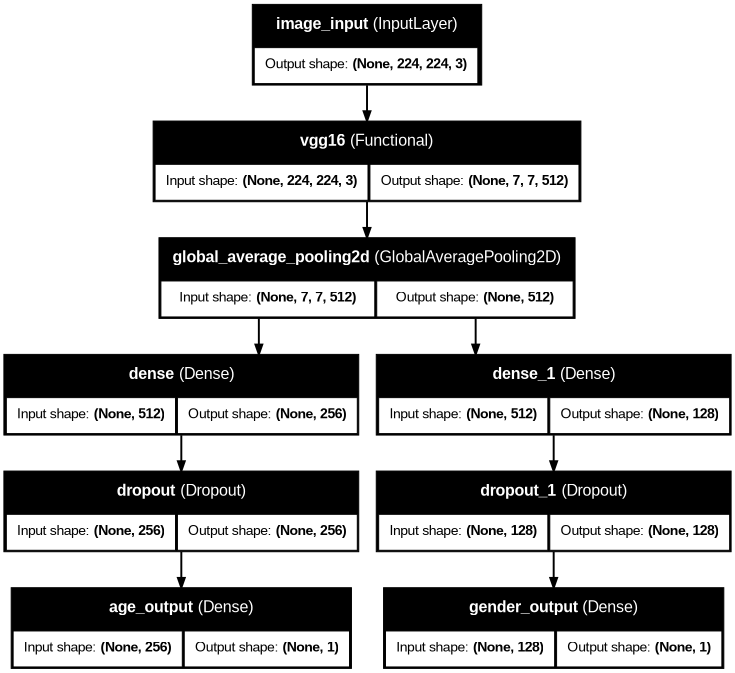

In [11]:
tf.keras.utils.plot_model(
    model,
    show_shapes=True,
    show_layer_names=True,
    dpi=70
)

In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss={
        "age_output": "mae",
        "gender_output": "binary_crossentropy"
    },
    loss_weights={
        "age_output": 1.0,
        "gender_output": 1.0
    },
    metrics={
        "age_output": ["mae"],
        "gender_output": ["accuracy"]
    }
)

In [13]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 300s 174ms/step - age_output_loss: 0.1011 - age_output_mae: 0.1011 - gender_output_accuracy: 0.8441 - gender_output_loss: 0.3598 - loss: 0.4610 - val_age_output_loss: 0.0684 - val_age_output_mae: 0.0685 - val_gender_output_accuracy: 0.8755 - val_gender_output_loss: 0.2835 - val_loss: 0.3519 - learning_rate: 0.0010
Epoch 2/10
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 313s 172ms/step - age_output_loss: 0.0702 - age_output_mae: 0.0701 - gender_output_accuracy: 0.8825 - gender_output_loss: 0.2781 - loss: 0.3482 - val_age_output_loss: 0.0690 - val_age_output_mae: 0.0691 - val_gender_output_accuracy: 0.8905 - val_gender_output_loss: 0.2578 - val_loss: 0.3271 - learning_rate: 0.0010
Epoch 3/10
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 287s 171ms/step - age_output_loss: 0.0665 - age_output_mae: 0.0665 - gender_output_accuracy: 0.9004 - gender_output_loss: 0.2437 - loss: 0.3102 - val_age_output_loss: 0.0621 - val_age_output_mae: 0.0622 - val_gender_output_accuracy: 0.9047 - 

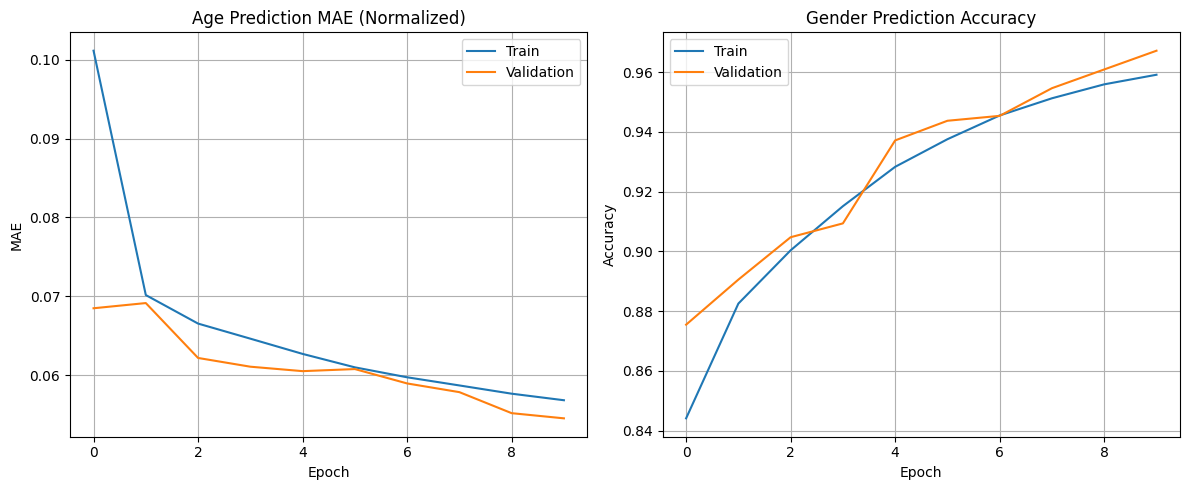

In [14]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["age_output_mae"], label="Train")
plt.plot(history.history["val_age_output_mae"], label="Validation")
plt.title("Age Prediction MAE (Normalized)")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["gender_output_accuracy"], label="Train")
plt.plot(history.history["val_gender_output_accuracy"], label="Validation")
plt.title("Gender Prediction Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [15]:
results = model.evaluate(test_ds, return_dict=True, verbose=1)

print(f"Test age MAE: {results['age_output_mae'] * MAX_AGE:.2f} years")
print(f"Test gender accuracy: {results['gender_output_accuracy'] * 100:.2f}%")

210/210 ━━━━━━━━━━━━━━━━━━━━ 34s 161ms/step - age_output_loss: 0.0533 - age_output_mae: 0.0534 - gender_output_accuracy: 0.9658 - gender_output_loss: 0.1085 - loss: 0.1621
Test age MAE: 6.19 years
Test gender accuracy: 96.58%


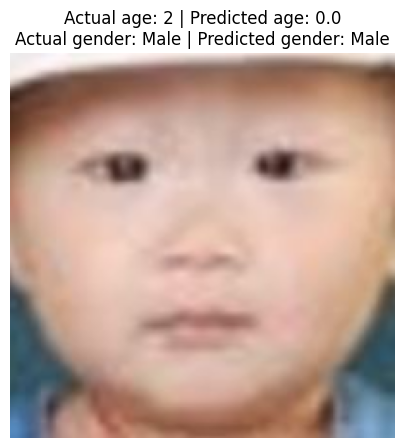

In [19]:
sample = test_df.sample(1, random_state=42).iloc[0]

image_bytes = tf.io.read_file(sample["img"])
image = tf.io.decode_jpeg(image_bytes, channels=3)
image = tf.image.resize(image, IMG_SIZE)

# VGG16 preprocessing
processed_image = preprocess_input(image.numpy())
prediction = model.predict(
    np.expand_dims(processed_image, axis=0),
    verbose=0
)

predicted_age = float(prediction[0][0][0]) * MAX_AGE
gender_probability = float(prediction[1][0][0])
predicted_gender = "Female" if gender_probability >= 0.5 else "Male"
actual_gender = "Female" if sample["gender"] == 1 else "Male"

plt.figure(figsize=(5, 5))
plt.imshow(image.numpy().astype("uint8"))
plt.title(
    f"Actual age: {sample['age']} | Predicted age: {predicted_age:.1f}\n"
    f"Actual gender: {actual_gender} | Predicted gender: {predicted_gender}"
)
plt.axis("off")
plt.show()

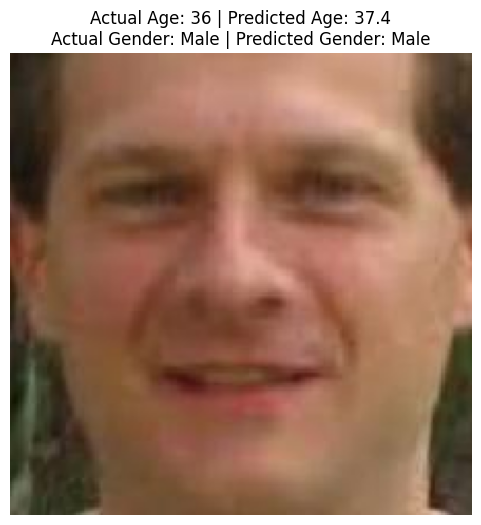

Predicted age: 37.4 years
Predicted gender: Male
Gender probability: 0.000


In [22]:
# Select any image from the test dataset
idx = 10  # Change this number to test another image
sample = test_df.iloc[idx]

# Load and preprocess image
img = tf.keras.utils.load_img(
    sample["img"],
    target_size=(224, 224)
)

img_array = tf.keras.utils.img_to_array(img)
img_array = preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

# Make predictions
predictions = model.predict(img_array, verbose=0)

predicted_age = float(predictions[0][0][0]) * MAX_AGE
gender_prob = float(predictions[1][0][0])
predicted_gender = "Female" if gender_prob >= 0.5 else "Male"

# Display image and results
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.title(
    f"Actual Age: {sample['age']} | Predicted Age: {predicted_age:.1f}\n"
    f"Actual Gender: {'Female' if sample['gender'] == 1 else 'Male'}"
    f" | Predicted Gender: {predicted_gender}"
)
plt.axis("off")
plt.show()

print(f"Predicted age: {predicted_age:.1f} years")
print(f"Predicted gender: {predicted_gender}")
print(f"Gender probability: {gender_prob:.3f}")